# Calling WGDs with MEDICC2

MEDICC2 models whole-genome doubling (WGD) explicitly. On every branch of the tree the copy numbers can change by
losses (including LOH) and gains before, between and after **up to two WGDs**:

* a WGD doubles every copy number of the genome (capped at 8, i.e. $c \to \min(2c, 8)$),
* a WGD costs **1** for the whole genome, like a single gain or loss of one segment.

A WGD is therefore called on a branch when doubling the genome explains the child with fewer events than gains
and losses alone. The calls come from the event reconstruction: run MEDICC2 with `--events` on the command line
or with `reconstruct_events=True` in python. Every WGD is one row of type `wgd` in the events table
(two rows if a branch has two WGDs), and the summary names the branches with a WGD.

```bash
medicc2 examples/gundem_et_al_2015/PTX011_input_df.tsv output_folder --events
# output_folder/PTX011_input_df_copynumber_events_df.tsv : rows with type == 'wgd'
# output_folder/PTX011_input_df_summary.tsv              : wgd_status
```

This notebook shows the same in python on the prostate cancer data of Gundem et al. 2015:

1. WGD calls on the tree of one patient,
2. the evidence for each call (how many events the WGD saves on its branch),
3. a quick per-sample check against the normal,
4. both calls for all patients,
5. a branch with two WGDs.

In [1]:
import logging
import os
import sys

import matplotlib.pyplot as plt
import pandas as pd

sys.path.append('..')
import medicc

logging.getLogger('medicc').setLevel(logging.ERROR)  # hide the segmentation-gap warnings of the input data

model = medicc.io.read_fst()                    # native model with WGD (the default)
model_nowgd = medicc.io.read_fst(no_wgd=True)   # the same model without WGD (losses and gains only)
model, model_nowgd

/home/cnie/schwarz_lab_folder/chenxi_conda/medicc2_pre_pub_env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


(ModelConfig(total_copy_numbers=False, no_wgd=False),
 ModelConfig(total_copy_numbers=False, no_wgd=True))

## 1. WGD calls on the tree

`medicc.main` with `reconstruct_events=True` reconstructs the tree, the ancestors and one minimum-cost event history
per branch. Branches with a WGD are the `sample_id`s of the rows with `type == 'wgd'`; all samples below such a
branch carry the WGD.

In [2]:
data_folder = '../examples/gundem_et_al_2015'
input_df = medicc.io.read_and_parse_input_data(os.path.join(data_folder, 'PTX011_input_df.tsv'))

sample_labels, pairwise_distances, nj_tree, final_tree, output_df, events_df = medicc.main(
    input_df, model, reconstruct_events=True)

wgd_events = events_df.loc[events_df['type'] == 'wgd']
n_wgd = wgd_events.index.get_level_values('sample_id').value_counts()   # number of WGDs per branch
for branch, n in n_wgd.items():
    below = [leaf.name for leaf in next(final_tree.find_clades(branch)).get_terminals()]
    print(f'{n} WGD on branch {branch}; samples below: {below}')

summary = medicc.summarize_patient(final_tree, pairwise_distances, sample_labels, events_df=events_df)
print('wgd_status:', summary['wgd_status'])
wgd_events.reset_index()[['sample_id', 'type', 'event_order', 'stage']]

1 WGD on branch internal2; samples below: ['RSubduralMet_A31A-0018_CRUK_PC_0018_M1', 'RIngLNMet_A31D-0018_CRUK_PC_0018_M2', 'RRib7Met_A31F-0018_CRUK_PC_0018_M4', 'LAdrenalMet_A31E-0018_CRUK_PC_0018_M3']
wgd_status: WGD on branch internal2


,sample_id,type,event_order,stage
0,internal2,wgd,8,2


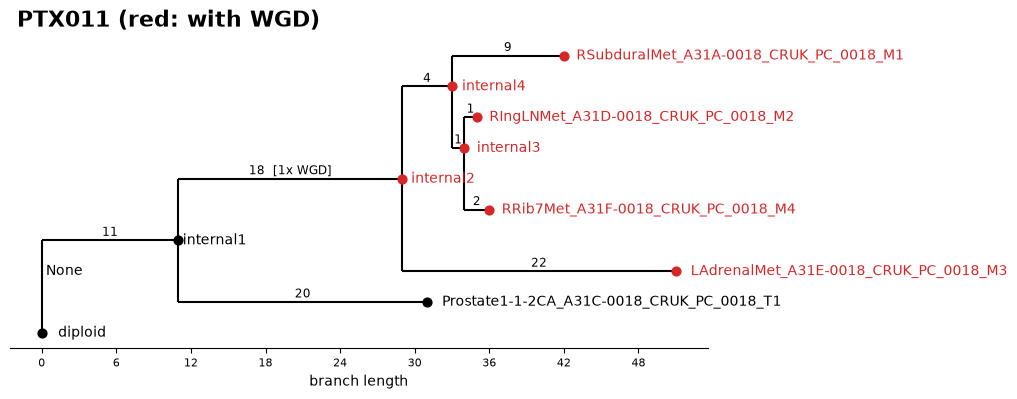

In [3]:
wgd_clades = [clade for branch in n_wgd.index for clade in next(final_tree.find_clades(branch)).find_clades()]
branch_labels = {clade: f'{clade.branch_length:g}' + (f'  [{n_wgd[clade.name]}x WGD]' if clade.name in n_wgd else '')
                 for clade in final_tree.find_clades() if clade.branch_length}

fig, ax = plt.subplots(figsize=(9, 4))
medicc.plot.plot_tree(final_tree, ax=ax, title='PTX011 (red: with WGD)', branch_labels=branch_labels,
                      label_colors={clade.name: 'tab:red' for clade in wgd_clades});

## 2. WGD evidence per branch

The length of a branch is the native directed score from the parent to the child profile, i.e. the minimum number of
events with the full model. `medicc.native.Model` gives direct access to this score. Scoring the same parent and
child with the no-WGD model gives the number of events needed without a WGD; the difference is the number of
events that allowing a WGD saves on the branch. A WGD is only called where it saves at least one event, and the
larger the saving, the stronger the evidence. The ancestors are kept fixed (they were reconstructed with the
full model).

In [4]:
def wgd_evidence(tree, cn_df, normal_name='diploid'):
    # Score parent -> child of every branch with and without WGD
    profiles = medicc.core.create_cn_str_dict(cn_df[['cn_a', 'cn_b']])
    rows = []
    with medicc.native.Model(model) as full, medicc.native.Model(model_nowgd) as nowgd:
        for parent in tree.find_clades():
            for child in parent.clades:
                if child.name == normal_name:
                    continue
                x, y = profiles[parent.name or normal_name], profiles[child.name]
                rows.append({'branch': child.name,
                             'score': full.score(x, y, directed=True),
                             'score_no_wgd': nowgd.score(x, y, directed=True)})
    evidence = pd.DataFrame(rows).set_index('branch')
    evidence['events_saved_by_wgd'] = evidence['score_no_wgd'] - evidence['score']
    return evidence.sort_values('events_saved_by_wgd', ascending=False)

wgd_evidence(final_tree, output_df)

,score,score_no_wgd,events_saved_by_wgd
branch,,,
internal2,18.0,48.0,30.0
internal1,11.0,11.0,0.0
Prostate1-1-2CA_A31C-0018_CRUK_PC_0018_T1,20.0,20.0,0.0
internal4,4.0,4.0,0.0
LAdrenalMet_A31E-0018_CRUK_PC_0018_M3,22.0,22.0,0.0
RSubduralMet_A31A-0018_CRUK_PC_0018_M1,9.0,9.0,0.0
internal3,1.0,1.0,0.0
RIngLNMet_A31D-0018_CRUK_PC_0018_M2,1.0,1.0,0.0
RRib7Met_A31F-0018_CRUK_PC_0018_M4,2.0,2.0,0.0


## 3. Quick per-sample check against the normal

Without a tree, every tumour sample can be compared directly with the normal: the directed score normal $\to$ sample
with and without WGD, and the number of WGDs in one minimum-cost history (`Model.history`). If the tree and the
ancestors are correct, a sample has a WGD here exactly when there is a WGD on its path from the normal in the tree.
For data where the tree is uncertain (e.g. many noisy single cells) this per-sample check is a useful cross-check.

In [5]:
def wgd_per_sample(input_df, normal_name='diploid'):
    # WGD call of every sample against the normal (no tree needed)
    profiles = medicc.core.create_cn_str_dict(input_df)
    normal = profiles.pop(normal_name)
    rows = {}
    with medicc.native.Model(model) as full, medicc.native.Model(model_nowgd) as nowgd:
        for sample, profile in profiles.items():
            score, stages = full.history(normal, profile)
            rows[sample] = {'n_wgd': sum(stage['type'] == 'wgd' for stage in stages),
                            'score': score,
                            'score_no_wgd': nowgd.score(normal, profile, directed=True)}
    result = pd.DataFrame.from_dict(rows, orient='index')
    result['events_saved_by_wgd'] = result['score_no_wgd'] - result['score']
    return result

wgd_per_sample(input_df)

,n_wgd,score,score_no_wgd,events_saved_by_wgd
LAdrenalMet_A31E-0018_CRUK_PC_0018_M3,1,48.0,76.0,28.0
Prostate1-1-2CA_A31C-0018_CRUK_PC_0018_T1,0,30.0,30.0,0.0
RIngLNMet_A31D-0018_CRUK_PC_0018_M2,1,29.0,55.0,26.0
RRib7Met_A31F-0018_CRUK_PC_0018_M4,1,32.0,58.0,26.0
RSubduralMet_A31A-0018_CRUK_PC_0018_M1,1,39.0,61.0,22.0


## 4. All patients: WGD from the tree vs. per sample

For every patient we run MEDICC2 with events, mark the samples below a WGD branch (`wgd_in_tree`) and compare
with the per-sample check.

In [6]:
patients = sorted(f.split('_')[0] for f in os.listdir(data_folder) if f.endswith('_input_df.tsv'))
status, samples = {}, []
for patient in patients:
    df = medicc.io.read_and_parse_input_data(os.path.join(data_folder, f'{patient}_input_df.tsv'))
    labels, pdm, _, tree, _, events = medicc.main(df, model, reconstruct_events=True)
    status[patient] = medicc.summarize_patient(tree, pdm, labels, events_df=events)['wgd_status']
    wgd_branches = events.loc[events['type'] == 'wgd'].index.get_level_values('sample_id')
    in_tree = {leaf.name for branch in wgd_branches for leaf in next(tree.find_clades(branch)).get_terminals()}
    per_sample = wgd_per_sample(df)
    samples.append(per_sample.assign(patient=patient, wgd_in_tree=per_sample.index.isin(in_tree)))
samples = pd.concat(samples)
samples['wgd_per_sample'] = samples['n_wgd'] > 0

display(pd.Series(status, name='wgd_status').to_frame())
samples.loc[samples['wgd_in_tree'] | samples['wgd_per_sample'],
            ['patient', 'wgd_in_tree', 'wgd_per_sample', 'events_saved_by_wgd']]

,wgd_status
PTX004,no WGD
PTX005,no WGD
PTX006,no WGD
PTX007,WGD on branch RRibNodularMet_A21F-0096_CRUK_PC...
PTX008,no WGD
PTX009,no WGD
PTX010,WGD on branch internal1
PTX011,WGD on branch internal2
PTX012,WGD on branch internal1
PTX013,no WGD


,patient,wgd_in_tree,wgd_per_sample,events_saved_by_wgd
RRibNodularMet_A21F-0096_CRUK_PC_0096_M5,PTX007,True,True,25.0
RAdrenalMet_A22F-0016_CRUK_PC_0016_M4,PTX008,False,True,1.0
ProstateCA_A29C-0017_CRUK_PC_0017_T1,PTX010,True,True,55.0
RSuperficialInguinalLNMetA1_A29A-0017_CRUK_PC_0017_M1,PTX010,True,True,62.0
LAdrenalMet_A31E-0018_CRUK_PC_0018_M3,PTX011,True,True,28.0
RIngLNMet_A31D-0018_CRUK_PC_0018_M2,PTX011,True,True,26.0
RRib7Met_A31F-0018_CRUK_PC_0018_M4,PTX011,True,True,26.0
RSubduralMet_A31A-0018_CRUK_PC_0018_M1,PTX011,True,True,22.0
LCervicalLNMet1-2_A32D-0019_CRUK_PC_0019_M2,PTX012,True,True,42.0
LSubclavicularLNMet1-5_A32E-0019_CRUK_PC_0019_M3,PTX012,True,True,25.0


Four patients have a WGD in the tree, and both approaches agree for all of their samples. The only difference is
one sample of PTX008: against the normal a WGD saves a single event, while in the tree its changes are shared with
other samples and no WGD is needed. A saving this small is weak evidence; such calls should be checked in the
copy-number profiles.

## 5. Two WGDs on one branch

A branch can carry up to two WGDs. As an illustration we add an artificial sample with copy number 4 on both
alleles everywhere (1 $\to$ 2 $\to$ 4: two WGDs, cost 2). Its branch has two `wgd` rows in the events table;
`event_order` and `stage` give the order of the events on the branch.

In [7]:
two_wgd = input_df.loc[['diploid']].rename(index={'diploid': 'two_WGD_sample'}, level='sample_id')
two_wgd[['cn_a', 'cn_b']] = '4'
input_df_two = pd.concat([input_df, two_wgd])

_, _, _, tree_two, _, events_two = medicc.main(input_df_two, model, reconstruct_events=True)
events_two.loc[events_two['type'] == 'wgd'].reset_index()[['sample_id', 'type', 'event_order', 'stage']]

,sample_id,type,event_order,stage
0,two_WGD_sample,wgd,1,2
1,two_WGD_sample,wgd,2,5
2,internal3,wgd,8,2
